## NB09 — Comparação dos Modelos e Construção do Ranking de Risco

**Entrada:** `data/load/dataset_ml_model.csv` — 75.471 linhas × 26 colunas  
**Saída:** `data/output/ranking_parcial.csv` — tabela ordenada de risco com scores dos 3 modelos

**Objetivo:**
- Comparar os modelos: sobreposição de anomalias, correlação de scores
- Construir o ranking combinado de risco
- Analisar o perfil das propostas mais anômalas

---
### 0. Imports e Configuração

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from scipy.stats import spearmanr

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 120
sns.set_style('whitegrid')

RANDOM_STATE = 42
CONTAMINATION = 0.01

os.makedirs('data/output', exist_ok=True)
print('Setup OK')

Setup OK


In [2]:
import os
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

os.makedirs('figuras_tcc', exist_ok=True)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['savefig.dpi'] = 200
plt.rcParams['axes.unicode_minus'] = True

def br(x, casas=0):
    """12345.678 -> '12.345,7' (ponto no milhar, vírgula decimal, sinal de menos correto)."""
    s = f'{round(x, casas) + 0.0:,.{casas}f}'  # '+ 0.0' evita '-0,00'
    return s.replace(',', '#').replace('.', ',').replace('#', '.').replace('-', '\u2212')

def fmt_eixo(ax, eixo='y', casas=0, pct=False):
    """Formato brasileiro nos números de um eixo. pct=True: multiplica por 100 e acrescenta '%'."""
    if pct:
        f = FuncFormatter(lambda v, _: br(v * 100, casas) + '%')
    else:
        f = FuncFormatter(lambda v, _: br(v, casas))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)

---
### 1. Carregamento e Separação de Identificadores

In [3]:
df_full = pd.read_csv('data/load/dataset_ml_model.csv')

print(f'Shape completo: {df_full.shape}')
print(f'\nColunas: {df_full.columns.tolist()}')

Shape completo: (75471, 26)

Colunas: ['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp', 'numeroItem', 'cnpj_forn_norm', 'desvio_item_estimado', 'n_propostas_item', 'fornecedor_unico', 'ano', 'mes', 'trimestre', 'dia_semana', 'dias_desde_eleicao', 'pre_eleitoral_180d', 'pos_eleitoral_180d', 'fornecedor_fora_pe', 'tipo_fornecedor', 'idade_empresa_anos', 'empresa_nova', 'opcao_pelo_mei', 'opcao_pelo_simples', 'modalidade_Dispensa', 'modalidade_Inexigibilidade', 'modalidade_Licitacao', 'porte', 'descricao_situacao_cadastral']


In [4]:
identificadores = ['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp',
                   'numeroItem', 'cnpj_forn_norm']

df_ids  = df_full[identificadores].copy()
df_feat = df_full.drop(columns=identificadores).copy()

feature_cols = df_feat.columns.tolist()

print(f'Features para modelagem ({len(feature_cols)}): {feature_cols}')
print(f'\nShape features: {df_feat.shape}')
print(f'NaN nas features: {df_feat.isnull().sum().sum()}')

Features para modelagem (21): ['desvio_item_estimado', 'n_propostas_item', 'fornecedor_unico', 'ano', 'mes', 'trimestre', 'dia_semana', 'dias_desde_eleicao', 'pre_eleitoral_180d', 'pos_eleitoral_180d', 'fornecedor_fora_pe', 'tipo_fornecedor', 'idade_empresa_anos', 'empresa_nova', 'opcao_pelo_mei', 'opcao_pelo_simples', 'modalidade_Dispensa', 'modalidade_Inexigibilidade', 'modalidade_Licitacao', 'porte', 'descricao_situacao_cadastral']

Shape features: (75471, 21)
NaN nas features: 0


---
### 2. Treinamento dos Modelos

Reprodução fiel dos hiperparâmetros definidos no NB08.

#### 2.1 Isolation Forest

In [5]:
print('Treinando Isolation Forest...')

iso_forest = IsolationForest(
    n_estimators=100,
    contamination=CONTAMINATION,
    max_samples=256,
    random_state=RANDOM_STATE
)
iso_forest.fit(df_feat)

df_feat['if_score']  = iso_forest.decision_function(df_feat[feature_cols])
df_feat['if_label']  = iso_forest.predict(df_feat[feature_cols])  # 1=normal, -1=anomalia

n_if = (df_feat['if_label'] == -1).sum()
print(f'IF → {n_if} anomalias ({n_if/len(df_feat):.1%})')

Treinando Isolation Forest...


IF → 743 anomalias (1.0%)


#### 2.2 Local Outlier Factor

O LOF compara densidades locais a partir de **distâncias entre registros**, então depende da escala das variáveis. Por isso as features são
padronizadas com `StandardScaler`, o mesmo tratamento do One-Class SVM (uma única matriz padronizada alimenta os dois modelos baseados em distância).
O Isolation Forest não precisa de padronização, porque seus cortes são feitos variável a variável. A comparação com o LOF sem padronização e com `RobustScaler` está na seção 2.4.

In [6]:
print('Treinando Local Outlier Factor...')

# LOF depende de distâncias: padroniza as features (StandardScaler, a mesma entrada do One-Class SVM).
# O Isolation Forest não precisa de padronização. Comparação com/sem padronização e com RobustScaler: seção 2.4.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_feat[feature_cols])

lof = LocalOutlierFactor(
    n_neighbors=50,
    contamination=CONTAMINATION
)
lof_preds  = lof.fit_predict(X_scaled)
lof_scores = -lof.negative_outlier_factor_

df_feat['lof_score'] = lof_scores
df_feat['lof_label'] = lof_preds  # 1=normal, -1=anomalia

n_lof = (df_feat['lof_label'] == -1).sum()
print(f'LOF → {n_lof} anomalias ({n_lof/len(df_feat):.1%})')


Treinando Local Outlier Factor...


LOF → 755 anomalias (1.0%)


#### 2.3 One-Class SVM (com StandardScaler)

In [7]:
# usa a mesma matriz padronizada (X_scaled) calculada para o LOF na seção 2.2

print('Treinando One-Class SVM...')
ocsvm = OneClassSVM(kernel='rbf', nu=CONTAMINATION, gamma='scale')
ocsvm.fit(X_scaled)

df_feat['ocsvm_score'] = ocsvm.decision_function(X_scaled)
df_feat['ocsvm_label'] = ocsvm.predict(X_scaled)  # 1=normal, -1=anomalia

n_ocsvm = (df_feat['ocsvm_label'] == -1).sum()
print(f'OCSVM → {n_ocsvm} anomalias ({n_ocsvm/len(df_feat):.1%})')

Treinando One-Class SVM...


OCSVM → 816 anomalias (1.1%)


#### 2.4 Sensibilidade do LOF ao escalonamento

Compara os conjuntos sinalizados pelo LOF **sem padronização**, com **`StandardScaler`** (adotado) e com **`RobustScaler`**. O LOF é determinístico, então a tabela é reprodutível
e fica salva em `data/output/comparacao_escalonamento_lof.csv`. A contaminação fixa (1%) faz os três tratamentos sinalizarem o mesmo número de registros; o que muda é **quais**.

O que a tabela mostra:
- **Sem padronização**, uma única variável concentra quase toda a variância bruta (`dias_desde_eleicao`) e a vizinhança de 50 registros é decidida por ela e pela idade da empresa,
  enquanto modalidade, origem do fornecedor e porte quase não pesam (veja a coluna de vizinhos com o mesmo perfil).
- **Padronizar** faz a vizinhança respeitar o perfil dos registros, e o conjunto sinalizado muda quase por completo (Jaccard baixo contra o tratamento sem padronização).
- **`RobustScaler` não trouxe ganho** sobre o `StandardScaler`: os conjuntos são parecidos e o `RobustScaler` deixa sem escala as colunas com IQR = 0 (inclusive `n_propostas_item`, que chega a 42).
  Também não há cauda tão pesada a ponto de o desvio-padrão ser inadequado (por exemplo, o desvio-padrão da idade da empresa é menor que o IQR).

**Decisão:** `StandardScaler`, o mesmo tratamento do One-Class SVM.

**Limitações:**
- Os registros duplicados (cerca de 31% das linhas) continuam dominando os escores extremos do LOF e independem da escala escolhida.
- Com a padronização, os registros **sem cadastro** (que compartilham o mesmo perfil imputado) ficam sobrerrepresentados entre as sinalizações do LOF (veja a linha "% sem cadastro", contra cerca de 25% da base).
  Isso vem da imputação e das duplicatas, não da escala, e fica pendente de tratamento próprio.

In [8]:
from sklearn.preprocessing import RobustScaler
from sklearn.neighbors import NearestNeighbors

bruto = df_feat[feature_cols].astype(float)

# (a) Amplitude das variáveis: o que o LOF "enxerga" sem padronização
amp = pd.DataFrame({'mínimo': bruto.min(), 'máximo': bruto.max(), 'desvio-padrão': bruto.std(),
                    'IQR': bruto.quantile(.75) - bruto.quantile(.25),
                    '% da variância bruta': bruto.var() / bruto.var().sum() * 100})
print('Variáveis com maior participação na variância bruta:')
print(amp.sort_values('% da variância bruta', ascending=False).head(4).round(3).to_string())
print(f'\nColunas com IQR = 0 (o RobustScaler não as escala): {[c for c in feature_cols if amp.loc[c, "IQR"] == 0]}')

# (b) LOF nos três tratamentos
entradas = {
    'Sem padronização':         bruto.to_numpy(),
    'StandardScaler (adotado)': X_scaled,
    'RobustScaler':             RobustScaler().fit_transform(bruto),
}
lof_var = {}
for nome, Z in entradas.items():
    m_lof = LocalOutlierFactor(n_neighbors=50, contamination=CONTAMINATION)
    flag = m_lof.fit_predict(Z) == -1
    lof_var[nome] = (-m_lof.negative_outlier_factor_, flag)

ref_score, ref_flag = lof_var['StandardScaler (adotado)']
if_flag = (df_feat['if_label'] == -1).to_numpy()
oc_flag = (df_feat['ocsvm_label'] == -1).to_numpy()
sem_cadastro = (df_feat['porte'] == 0).to_numpy()

# (c) A vizinhança respeita o perfil? % dos 50 vizinhos com o mesmo valor da consulta (2.000 consultas, semente fixa)
q = np.random.RandomState(RANDOM_STATE).choice(len(bruto), 2000, replace=False)
perfil = ['modalidade_Dispensa', 'fornecedor_fora_pe', 'porte']

linhas = []
for nome, Z in entradas.items():
    score, flag = lof_var[nome]
    viz = NearestNeighbors(n_neighbors=51).fit(Z).kneighbors(Z[q], return_distance=False)[:, 1:]
    linha = {'Tratamento': nome, 'Sinalizadas': int(flag.sum()),
             'Jaccard vs adotado': (flag & ref_flag).sum() / (flag | ref_flag).sum(),
             'Spearman dos escores vs adotado': spearmanr(score, ref_score)[0],
             '% sem cadastro': sem_cadastro[flag].mean() * 100,
             'Também no IF': int((flag & if_flag).sum()), 'Também no OCSVM': int((flag & oc_flag).sum())}
    for c in perfil:
        v = bruto[c].to_numpy()
        linha[f'% vizinhos c/ mesma {c}'] = (v[viz] == v[q][:, None]).mean() * 100
    linhas.append(linha)

comp_lof = pd.DataFrame(linhas).set_index('Tratamento')
print('\n=== LOF: sem padronização × StandardScaler × RobustScaler ===')
print(comp_lof.round(2).T.to_string())
print(f'\n(base: {sem_cadastro.mean()*100:.1f}% das linhas sem cadastro)')

comp_lof.round(4).to_csv('data/output/comparacao_escalonamento_lof.csv')
print('Salvo em data/output/comparacao_escalonamento_lof.csv')


Variáveis com maior participação na variância bruta:
                    mínimo   máximo  desvio-padrão      IQR  % da variância bruta
dias_desde_eleicao  -641.0   85.000        173.147  274.000                99.494
idade_empresa_anos     0.0  116.331         11.465   14.418                 0.436
mes                    1.0   12.000          3.103    5.000                 0.032
n_propostas_item       1.0   42.000          2.266    0.000                 0.017

Colunas com IQR = 0 (o RobustScaler não as escala): ['n_propostas_item', 'fornecedor_unico', 'pos_eleitoral_180d', 'tipo_fornecedor', 'empresa_nova', 'opcao_pelo_mei', 'modalidade_Dispensa', 'modalidade_Inexigibilidade', 'descricao_situacao_cadastral']



=== LOF: sem padronização × StandardScaler × RobustScaler ===
Tratamento                               Sem padronização  StandardScaler (adotado)  RobustScaler
Sinalizadas                                        755.00                    755.00        755.00
Jaccard vs adotado                                   0.07                      1.00          0.62
Spearman dos escores vs adotado                      0.37                      1.00          0.80
% sem cadastro                                      26.89                     68.61         60.66
Também no IF                                        67.00                     56.00         56.00
Também no OCSVM                                      6.00                     20.00         16.00
% vizinhos c/ mesma modalidade_Dispensa             86.13                     99.79         99.50
% vizinhos c/ mesma fornecedor_fora_pe              80.16                     98.67         97.72
% vizinhos c/ mesma porte                           74.

---
### 3. Tabela Comparativa Inicial

In [9]:
comparativo = pd.DataFrame({
    'Modelo': ['Isolation Forest', 'Local Outlier Factor', 'One-Class SVM'],
    'Hiperparâmetros': [
        'n_estimators=100, max_samples=256, contamination=0.01',
        'n_neighbors=50, contamination=0.01 + StandardScaler',
        'kernel=rbf, nu=0.01, gamma=scale + StandardScaler'
    ],
    'Anomalias Detectadas': [
        (df_feat['if_label'] == -1).sum(),
        (df_feat['lof_label'] == -1).sum(),
        (df_feat['ocsvm_label'] == -1).sum()
    ],
    '% da Base': [
        f"{(df_feat['if_label'] == -1).mean():.2%}",
        f"{(df_feat['lof_label'] == -1).mean():.2%}",
        f"{(df_feat['ocsvm_label'] == -1).mean():.2%}"
    ]
})

print('=== Tabela Comparativa dos Modelos ===')
print(comparativo.to_string(index=False))

=== Tabela Comparativa dos Modelos ===
              Modelo                                       Hiperparâmetros  Anomalias Detectadas % da Base
    Isolation Forest n_estimators=100, max_samples=256, contamination=0.01                   743     0.98%
Local Outlier Factor   n_neighbors=50, contamination=0.01 + StandardScaler                   755     1.00%
       One-Class SVM     kernel=rbf, nu=0.01, gamma=scale + StandardScaler                   816     1.08%


---
### 4. Análise de Sobreposição (Overlap)

Quantas propostas são sinalizadas por 1, 2 ou 3 modelos simultaneamente?

In [10]:
set_if    = set(df_feat[df_feat['if_label']    == -1].index)
set_lof   = set(df_feat[df_feat['lof_label']   == -1].index)
set_ocsvm = set(df_feat[df_feat['ocsvm_label'] == -1].index)

todos_3    = set_if & set_lof & set_ocsvm
if_lof     = (set_if & set_lof)    - todos_3
if_ocsvm   = (set_if & set_ocsvm)  - todos_3
lof_ocsvm  = (set_lof & set_ocsvm) - todos_3
so_if      = set_if    - set_lof - set_ocsvm
so_lof     = set_lof   - set_if  - set_ocsvm
so_ocsvm   = set_ocsvm - set_if  - set_lof

print('=== Sobreposição entre Modelos ===')
print(f'Flagados pelos 3 modelos:       {len(todos_3):>5} ({len(todos_3)/len(df_feat):.3%})')
print(f'Apenas IF + LOF:                {len(if_lof):>5} ({len(if_lof)/len(df_feat):.3%})')
print(f'Apenas IF + OCSVM:              {len(if_ocsvm):>5} ({len(if_ocsvm)/len(df_feat):.3%})')
print(f'Apenas LOF + OCSVM:             {len(lof_ocsvm):>5} ({len(lof_ocsvm)/len(df_feat):.3%})')
print(f'Apenas IF:                      {len(so_if):>5} ({len(so_if)/len(df_feat):.3%})')
print(f'Apenas LOF:                     {len(so_lof):>5} ({len(so_lof)/len(df_feat):.3%})')
print(f'Apenas OCSVM:                   {len(so_ocsvm):>5} ({len(so_ocsvm)/len(df_feat):.3%})')
print(f'\nUnião total (≥1 modelo):        {len(set_if|set_lof|set_ocsvm):>5} ({len(set_if|set_lof|set_ocsvm)/len(df_feat):.3%})')

=== Sobreposição entre Modelos ===
Flagados pelos 3 modelos:           1 (0.001%)
Apenas IF + LOF:                   55 (0.073%)
Apenas IF + OCSVM:                287 (0.380%)
Apenas LOF + OCSVM:                19 (0.025%)
Apenas IF:                        400 (0.530%)
Apenas LOF:                       680 (0.901%)
Apenas OCSVM:                     509 (0.674%)

União total (≥1 modelo):         1951 (2.585%)


In [11]:
df_feat['votos'] = (
    (df_feat['if_label']    == -1).astype(int) +
    (df_feat['lof_label']   == -1).astype(int) +
    (df_feat['ocsvm_label'] == -1).astype(int)
)

votos_dist = df_feat['votos'].value_counts().sort_index()
print('=== Distribuição de Votos ===')
for v, n in votos_dist.items():
    label = {
        0: 'Normal (nenhum modelo)',
        1: 'Baixo risco (1 modelo)',
        2: 'Médio risco (2 modelos)',
        3: 'Alto risco (3 modelos)'
    }[v]
    print(f'  {v} voto(s) — {label}: {n:>6} ({n/len(df_feat):.2%})')

=== Distribuição de Votos ===
  0 voto(s) — Normal (nenhum modelo):  73520 (97.41%)
  1 voto(s) — Baixo risco (1 modelo):   1589 (2.11%)
  2 voto(s) — Médio risco (2 modelos):    361 (0.48%)
  3 voto(s) — Alto risco (3 modelos):      1 (0.00%)


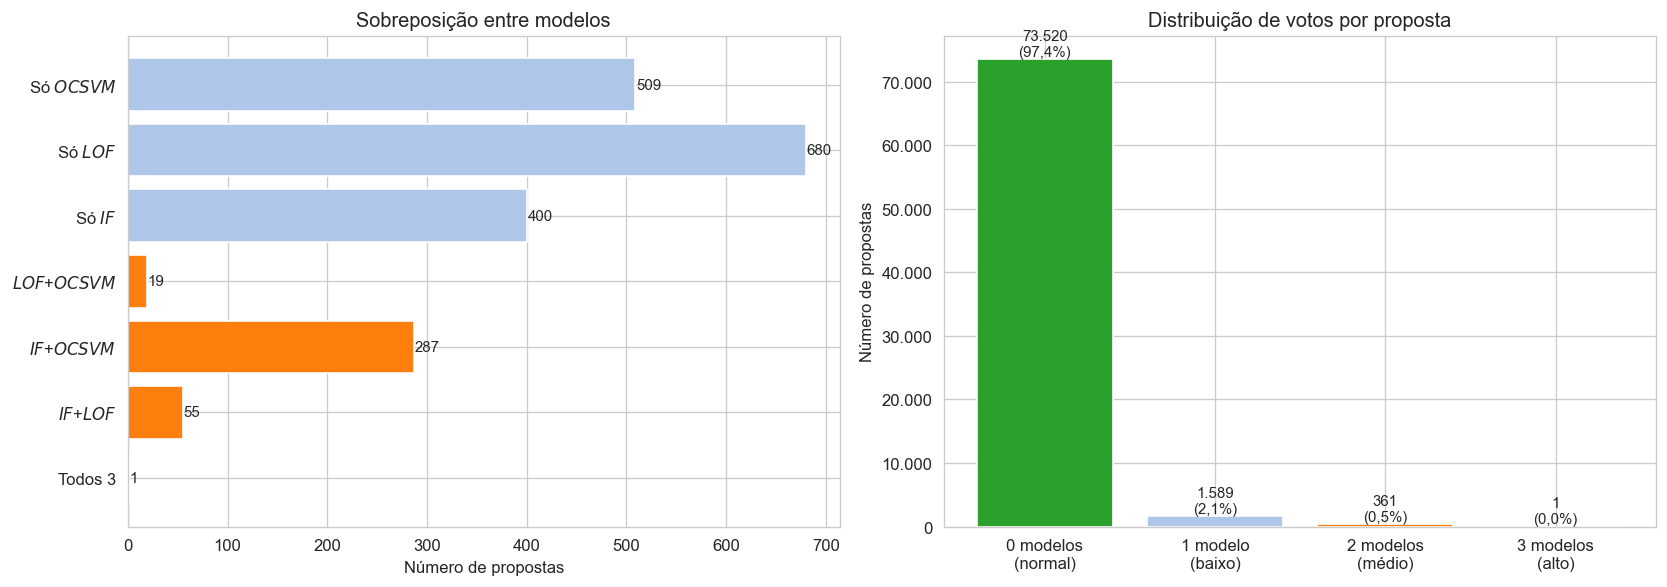

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

IF_, LOF_, OCSVM_ = r'$\mathit{IF}$', r'$\mathit{LOF}$', r'$\mathit{OCSVM}$'
labels_overlap = [
    'Todos 3', f'{IF_}+{LOF_}', f'{IF_}+{OCSVM_}', f'{LOF_}+{OCSVM_}',
    f'Só {IF_}', f'Só {LOF_}', f'Só {OCSVM_}'
]
counts_overlap = [
    len(todos_3), len(if_lof), len(if_ocsvm), len(lof_ocsvm),
    len(so_if), len(so_lof), len(so_ocsvm)
]
colors = ['#d62728', '#ff7f0e', '#ff7f0e', '#ff7f0e', '#aec7e8', '#aec7e8', '#aec7e8']
axes[0].barh(labels_overlap, counts_overlap, color=colors)
axes[0].set_xlabel('Número de propostas')
axes[0].set_title('Sobreposição entre modelos')
for i, v in enumerate(counts_overlap):
    axes[0].text(v + 1, i, br(v, 0), va='center', fontsize=9)
fmt_eixo(axes[0], 'x', 0)

votos_colors = ['#2ca02c', '#aec7e8', '#ff7f0e', '#d62728']
votos_labels = ['0 modelos\n(normal)', '1 modelo\n(baixo)', '2 modelos\n(médio)', '3 modelos\n(alto)']
bars = axes[1].bar(votos_labels, votos_dist.values, color=votos_colors)
axes[1].set_title('Distribuição de votos por proposta')
axes[1].set_ylabel('Número de propostas')
for bar, val in zip(bars, votos_dist.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                 f'{br(val, 0)}\n({br(val/len(df_feat)*100, 1)}%)',
                 ha='center', va='bottom', fontsize=9)
fmt_eixo(axes[1], 'y', 0)

plt.tight_layout()
plt.savefig('data/output/fig_sobreposicao_modelos.png', bbox_inches='tight')
plt.show()

---
### 5. Construção do Ranking Combinado

**Critérios:**
1. **Votos** (primário): quantos dos 3 modelos sinalizaram a proposta como anômala
2. **Score combinado normalizado** (desempate): média dos 3 scores após normalização MinMax

In [13]:
mms = MinMaxScaler()

df_feat['if_score_norm']    = mms.fit_transform(-df_feat[['if_score']])    
df_feat['lof_score_norm']   = mms.fit_transform(df_feat[['lof_score']])
df_feat['ocsvm_score_norm'] = mms.fit_transform(-df_feat[['ocsvm_score']]) 

df_feat['score_combinado'] = df_feat[[
    'if_score_norm', 'lof_score_norm', 'ocsvm_score_norm'
]].mean(axis=1)

print(f'Score combinado — min: {df_feat["score_combinado"].min():.4f}, '
      f'max: {df_feat["score_combinado"].max():.4f}, '
      f'mediana: {df_feat["score_combinado"].median():.4f}')

Score combinado — min: 0.0281, max: 0.6854, mediana: 0.1754


In [14]:
df_ranking = pd.concat([
    df_ids.reset_index(drop=True),
    df_feat[[
        'if_score', 'if_label', 'if_score_norm',
        'lof_score', 'lof_label', 'lof_score_norm',
        'ocsvm_score', 'ocsvm_label', 'ocsvm_score_norm',
        'votos', 'score_combinado'
    ]].reset_index(drop=True)
], axis=1)

df_ranking = df_ranking.sort_values(
    ['votos', 'score_combinado'],
    ascending=[False, False]
).reset_index(drop=True)

df_ranking['posicao_risco'] = df_ranking.index + 1  # 1 = mais anômalo

print(f'Ranking construído: {len(df_ranking)} propostas')
print(f'\nTop 10 — propostas com maior risco:')
df_ranking[['posicao_risco', 'cnpj_forn_norm', 'orgaoEntidadeCnpj',
            'votos', 'score_combinado']].head(10)

Ranking construído: 75471 propostas

Top 10 — propostas com maior risco:


,posicao_risco,cnpj_forn_norm,orgaoEntidadeCnpj,votos,score_combinado
0,1,1312191465,394452000103,3,0.685438
1,2,28986001694,394460000141,2,0.668076
2,3,28986001694,33781055000135,2,0.662122
3,4,28986001694,33781055000135,2,0.662122
4,5,12678560414,10260222000105,2,0.649633
5,6,12385465442,10260222000105,2,0.615535
6,7,12385465442,10260222000105,2,0.615100
7,8,28986001694,2030715000112,2,0.615030
8,9,52105018000151,10571982000125,2,0.576410
9,10,51026267000199,24416174000106,2,0.546484


In [15]:
df_ranking.to_csv('data/output/ranking_parcial.csv', index=False)
print(f'Ranking salvo em data/output/ranking_parcial.csv ({len(df_ranking)} linhas)')

Ranking salvo em data/output/ranking_parcial.csv (75471 linhas)


---
### 6. Análise do Perfil das Propostas de Alto Risco

In [16]:
alto_risco = df_ranking[df_ranking['votos'] >= 2].copy()
normal     = df_ranking[df_ranking['votos'] == 0].copy()

print(f'Propostas de alto risco (≥2 modelos): {len(alto_risco)} ({len(alto_risco)/len(df_ranking):.2%})')
print(f'  - Flagadas pelos 3 modelos: {(alto_risco["votos"] == 3).sum()}')
print(f'  - Flagadas por 2 modelos:   {(alto_risco["votos"] == 2).sum()}')
print(f'\nTotal normal (0 votos): {len(normal)} ({len(normal)/len(df_ranking):.2%})')

Propostas de alto risco (≥2 modelos): 362 (0.48%)
  - Flagadas pelos 3 modelos: 1
  - Flagadas por 2 modelos:   361

Total normal (0 votos): 73520 (97.41%)


In [17]:
df_perfil = df_full.copy()
df_perfil['votos']          = df_feat['votos'].values
df_perfil['score_combinado'] = df_feat['score_combinado'].values

# nome da modalidade (para os gráficos), reconstruído a partir das dummies usadas nos modelos
mod_cols = ['modalidade_Dispensa', 'modalidade_Inexigibilidade', 'modalidade_Licitacao']
df_perfil['modalidade'] = (df_perfil[mod_cols].idxmax(axis=1)
                           .str.replace('modalidade_', '', regex=False)
                           .replace({'Licitacao': 'Licitação'}))

alto = df_perfil[df_perfil['votos'] >= 2]
norm = df_perfil[df_perfil['votos'] == 0]

print(f'Alto risco (≥2 votos): {len(alto)} propostas ({len(alto)/len(df_perfil):.2%})')
print(f'Normal (0 votos): {len(norm)} propostas ({len(norm)/len(df_perfil):.2%})')

Alto risco (≥2 votos): 362 propostas (0.48%)
Normal (0 votos): 73520 propostas (97.41%)


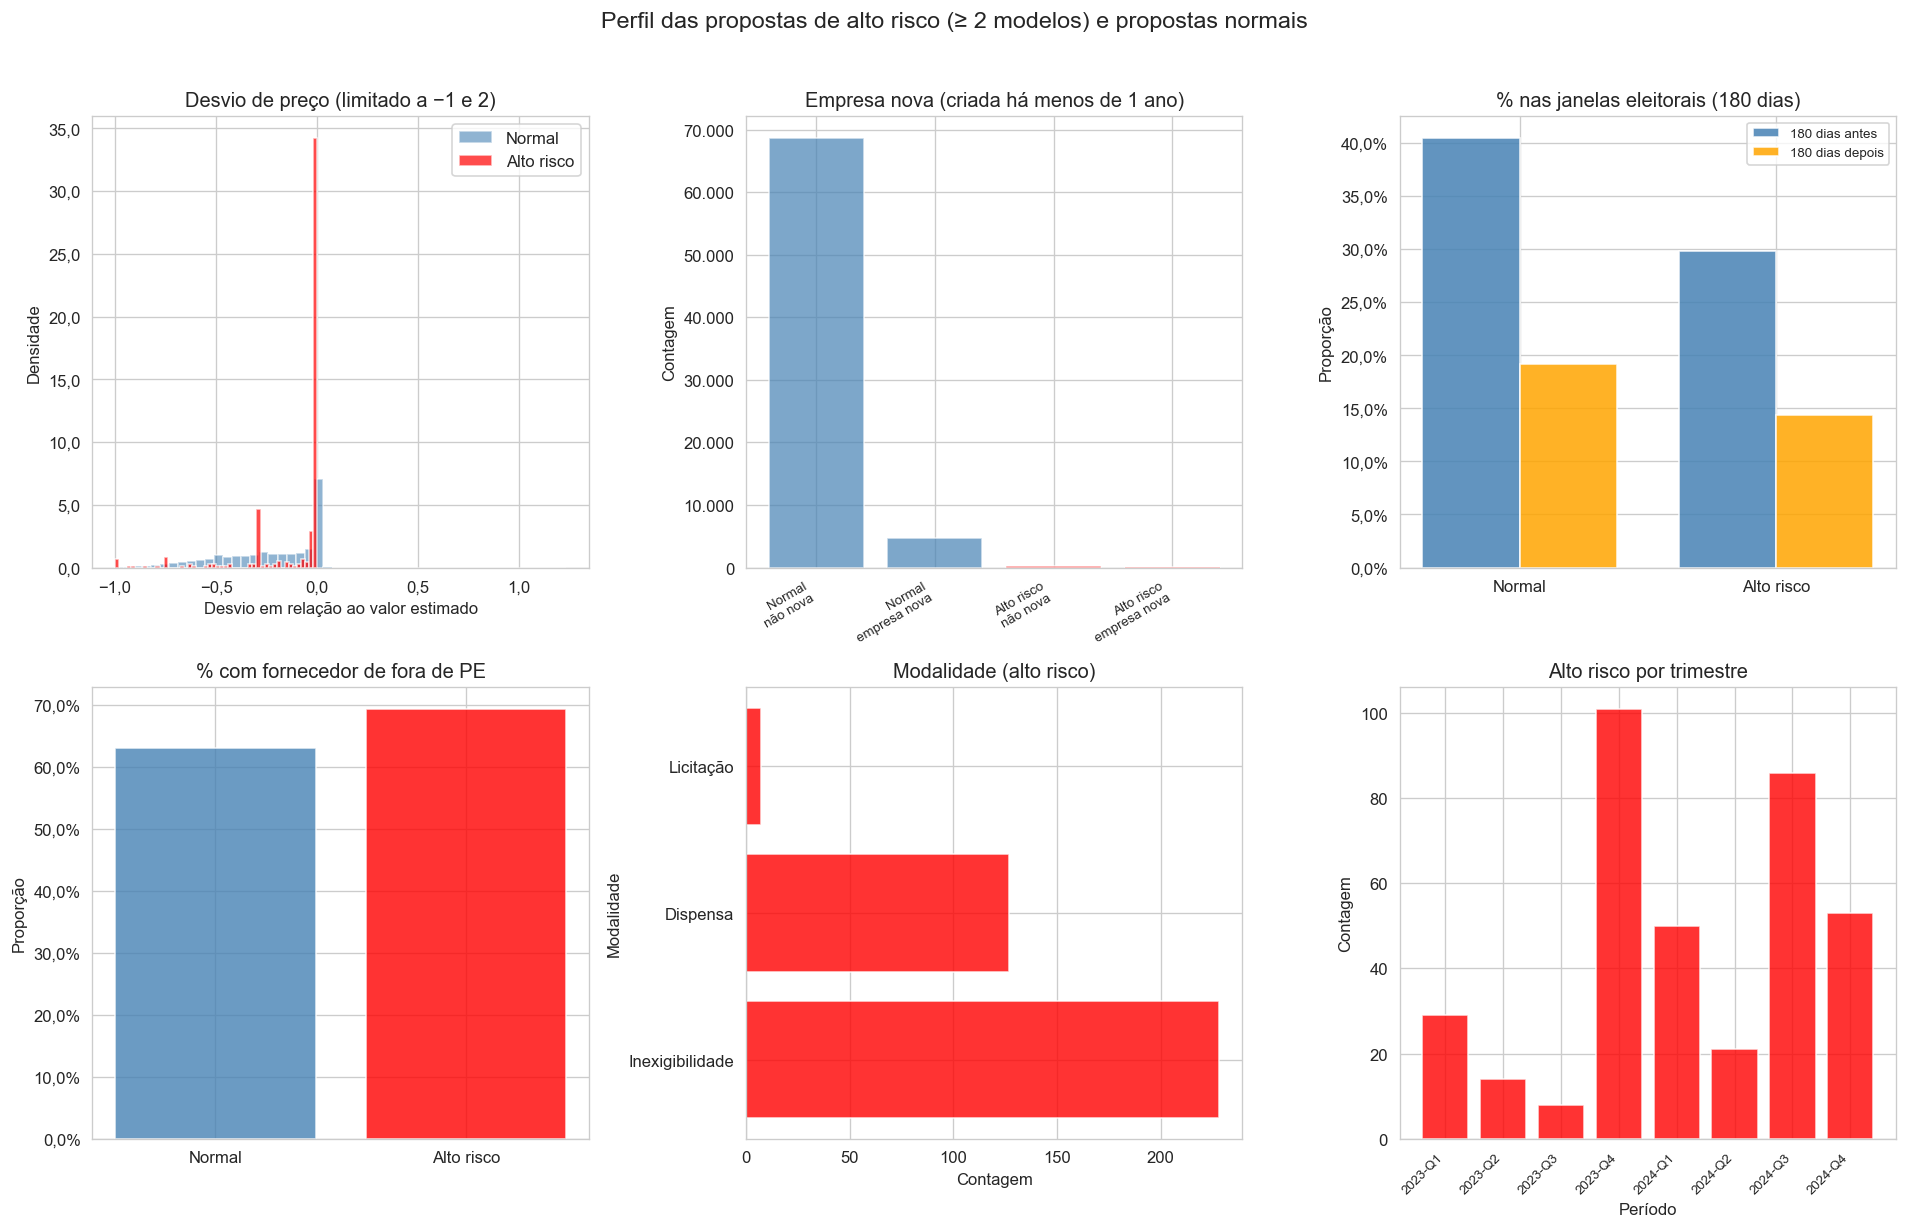

Figura salva em data/output/fig_perfil_alto_risco.png


In [18]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# 1. Desvio de preço
axes[0,0].hist(norm['desvio_item_estimado'].clip(-1, 2),
               bins=50, alpha=0.6, label='Normal', color='steelblue', density=True)
axes[0,0].hist(alto['desvio_item_estimado'].clip(-1, 2),
               bins=50, alpha=0.7, label='Alto risco', color='red', density=True)
axes[0,0].set_title('Desvio de preço (limitado a \u22121 e 2)')
axes[0,0].set_xlabel('Desvio em relação ao valor estimado')
axes[0,0].set_ylabel('Densidade')
axes[0,0].legend()
fmt_eixo(axes[0,0], 'x', 1)
fmt_eixo(axes[0,0], 'y', 1)

# 2. Empresa nova
for group, lbl, color in [(norm, 'Normal', 'steelblue'), (alto, 'Alto risco', 'red')]:
    axes[0,1].bar([lbl + '\nnão nova', lbl + '\nempresa nova'],
                  [(group['empresa_nova'] == 0).sum(), (group['empresa_nova'] == 1).sum()],
                  color=color, alpha=0.7)
axes[0,1].set_title('Empresa nova (criada há menos de 1 ano)')
axes[0,1].set_ylabel('Contagem')
fmt_eixo(axes[0,1], 'y', 0)
plt.setp(axes[0,1].get_xticklabels(), rotation=30, ha='right', fontsize=8)

# 3. Janelas eleitorais (180 dias antes e depois da eleição)
x = np.arange(2); w = 0.38
pre_vals = [(norm['pre_eleitoral_180d'] == 1).mean(), (alto['pre_eleitoral_180d'] == 1).mean()]
pos_vals = [(norm['pos_eleitoral_180d'] == 1).mean(), (alto['pos_eleitoral_180d'] == 1).mean()]
axes[0,2].bar(x - w/2, pre_vals, w, label='180 dias antes', color='steelblue', alpha=0.85)
axes[0,2].bar(x + w/2, pos_vals, w, label='180 dias depois', color='orange', alpha=0.85)
axes[0,2].set_xticks(x)
axes[0,2].set_xticklabels(['Normal', 'Alto risco'])
axes[0,2].set_title('% nas janelas eleitorais (180 dias)')
axes[0,2].set_ylabel('Proporção')
axes[0,2].legend(fontsize=8)
fmt_eixo(axes[0,2], 'y', 1, pct=True)

# 4. Fornecedor fora de PE
fpe_norm = (norm['fornecedor_fora_pe'] == 1).mean()
fpe_alto = (alto['fornecedor_fora_pe'] == 1).mean()
axes[1,0].bar(['Normal', 'Alto risco'], [fpe_norm, fpe_alto],
              color=['steelblue', 'red'], alpha=0.8)
axes[1,0].set_title('% com fornecedor de fora de PE')
axes[1,0].set_ylabel('Proporção')
fmt_eixo(axes[1,0], 'y', 1, pct=True)

# 5. Modalidade
mod_alto = alto['modalidade'].value_counts()
axes[1,1].barh(mod_alto.index, mod_alto.values, color='red', alpha=0.8)
axes[1,1].set_title('Modalidade (alto risco)')
axes[1,1].set_xlabel('Contagem')
axes[1,1].set_ylabel('Modalidade')
fmt_eixo(axes[1,1], 'x', 0)

# 6. Distribuição temporal (votos ≥2 por trimestre)
alto_trim = alto.groupby(['ano', 'trimestre']).size().reset_index(name='n')
alto_trim['periodo'] = alto_trim['ano'].astype(str) + '-Q' + alto_trim['trimestre'].astype(str)
axes[1,2].bar(alto_trim['periodo'], alto_trim['n'], color='red', alpha=0.8)
axes[1,2].set_title('Alto risco por trimestre')
axes[1,2].set_xlabel('Período')
axes[1,2].set_ylabel('Contagem')
fmt_eixo(axes[1,2], 'y', 0)
plt.setp(axes[1,2].get_xticklabels(), rotation=45, ha='right', fontsize=8)

plt.suptitle('Perfil das propostas de alto risco (≥ 2 modelos) e propostas normais', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('data/output/fig_perfil_alto_risco.png', bbox_inches='tight')
plt.savefig('figuras_tcc/image4.png', dpi=200, bbox_inches='tight')
plt.show()
print('Figura salva em data/output/fig_perfil_alto_risco.png')

---
### 7. Top-20 da Tabela de Risco

In [19]:
top20_ids = df_ranking.head(20)[['posicao_risco', 'orgaoEntidadeCnpj', 'cnpj_forn_norm',
                                  'anoCompraPncp', 'sequencialCompraPncp', 'numeroItem',
                                  'votos', 'score_combinado']].copy()

top20_completo = top20_ids.merge(
    df_perfil[['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp', 'numeroItem',
               'cnpj_forn_norm', 'desvio_item_estimado', 'modalidade',
               'empresa_nova', 'fornecedor_fora_pe', 'pre_eleitoral_180d',
               'dias_desde_eleicao', 'idade_empresa_anos']],
    on=['orgaoEntidadeCnpj', 'anoCompraPncp', 'sequencialCompraPncp',
        'numeroItem', 'cnpj_forn_norm'],
    how='left'
)

print('=== Top 20 Propostas de Maior Risco ===')
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 200)
top20_completo

=== Top 20 Propostas de Maior Risco ===


,posicao_risco,orgaoEntidadeCnpj,cnpj_forn_norm,anoCompraPncp,sequencialCompraPncp,numeroItem,votos,score_combinado,desvio_item_estimado,modalidade,empresa_nova,fornecedor_fora_pe,pre_eleitoral_180d,dias_desde_eleicao,idade_empresa_anos
0,1,394452000103,1312191465,2023,13340,1,3,0.685438,0.0,Dispensa,0,1,0,-318,28.804928
1,2,394460000141,28986001694,2023,534,1,2,0.668076,0.0,Inexigibilidade,0,0,0,-489,27.266256
2,3,33781055000135,28986001694,2024,1135,1,2,0.662122,0.0,Inexigibilidade,0,0,1,-90,28.358658
3,4,33781055000135,28986001694,2024,1138,1,2,0.662122,0.0,Inexigibilidade,0,0,1,-90,28.358658
4,5,10260222000105,12678560414,2024,13,1,2,0.649633,0.0,Dispensa,0,1,0,-258,28.804928
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,20,508903000188,0,2024,3392,1,2,0.539567,0.0,Inexigibilidade,0,1,0,85,28.804928
106,20,508903000188,0,2024,3392,1,2,0.539567,0.0,Inexigibilidade,0,1,0,85,28.804928
107,20,508903000188,0,2024,3392,1,2,0.539567,0.0,Inexigibilidade,0,1,0,85,28.804928
108,20,508903000188,0,2024,3392,1,2,0.539567,0.0,Inexigibilidade,0,1,0,85,28.804928
